# AERIS: Terrain-Aware Antenna Comparison
**Mehmet Karaman | Autonomous UAV firefighting simulation**

This reproducible study compares seven idealized antenna configurations across four mission environments. It explains **which antenna family is more useful for each terrain in the simulated tests**, using recorded flight geometry, synthetic mission variations and independent random test samples.

These are model-based comparisons, not physical RF measurements or validated commercial-product recommendations. All patterns and environmental coefficients are explicitly assumed. Relative performance does not establish operational suitability.

[UAV project](https://github.com/mehmetkaramaan/aeris-uav-showcase)

## 1. Reproducibility and flight data
CPU execution only; no external downloads are needed. The embedded data contains 551 local-position/attitude samples from a completed Gazebo/PX4 simulation. Absolute GPS coordinates and integrated flight-control code are excluded. Run all cells to regenerate the tables, figures and JSON results.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json,base64,gzip,math
from pathlib import Path
from IPython.display import display,Markdown
OUT=Path('/kaggle/working/antenna_results') if Path('/kaggle/working').exists() else Path('antenna_results')
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
COLORS=['#354c5e','#4c775f','#9c7840','#8c5860','#6c6190','#327f8b','#727234']
def figure(name):
    plt.savefig(OUT/(name+'.png'),dpi=180,bbox_inches='tight')
    plt.show()


In [2]:
PAYLOAD = 'H4sIAAAAAAAC/1192441O2/cu/zX61uQSB3zKoYvgsCIDRhx4PguyLunqkhq9uybbmFNt1qHYrFIqXv+7z/+6x//7Z/2t/nnfNv4XB5607F/2/x0+7b16a7j0HF+2/709W3n07eOR0fcez/WdOzf/jHjwXkY347j1HF9u31s63i+3T92efSmI24cH8ed8+OuI+5dH8e9++NLR9x7Po5778cvj6N97TP61/pnmI7+NfwydJxf889YXxufsb82P+PoeL+2PrPpiHv3Z5qOuPd85tAR997PXDrur3/m4eF+vX9W07F/3T7LdPSv+2eNr4/Pmjqur8/P2joeHXHv+uymI+7dn2064t7z2bj3fvbUcX3HZ+/v6J99dLzfYZ/TdOzfgSmz7xif4zqO75ifM79jfc7SEffuzzk64t7zubj3fm7X0b7zc/07++cOHaeO6zvtc/d3AgznO3HN5bG39p2Y9tbjZHHC/Zj5NuKEGi5O6wuUtP1dHacTp/tdBki173Kcepzsu4gzj9P4LjwH8NIJlaAWAGzhOUCYTqgFzwHGFp4DkOlkX/wJOONxfDeeBqTptL4bDwXWNp4GsOl0vxtPA9w2HgO86YQ6iHJUgloAOZ1QC54G0G08BqjT6Xz52/0ePAC406l/D54D6B08ANjTaXwPngP06bS+B88B/nRCJTSnqxMgePA4YPCgaoDw4DlAoU4jTvPL49Jxfy8eCiRePBRYvHgawKhT/148DXC8eAzwqNP4XjwGiLy02xUn1IKnAZQ6oRZUDUA2HE1HmDweA0Q2PAaQ1GmRKTpQSYIALMkQwCVpAcAkLwCZogSLk5MOOsCJuo4IoAOdOokC+hEH9CMS6EAo7L8DojD9fi1OTgrogCmsvwOnnWyz4rRJAB1QRV2AKozfAFXYvQGqMHwDVHVyEoABqrB9A1Rh9gaowuINWNXp0OYNWDVSWIsTjBRHo7EboAo7N0BVp0l7N0AVpm5dVm79xEl2boAqjNsAVVi3AaowbANWcT2wyuOkaRugCqs2QBVmbYDq4N8uTdoAVZ06jdoAVdizAaowaANUYcsGqOoE48Vx05ANSIUlG6A6USWgCos2QBXGbIDqRF2AKqzYAFWdZL4GqOoEy8Px6HhpxAagwohtynptynoNQIW9GoAKezUAFYZqQCoM1QBVnQ4N1QBV/AlI3fQCPU5GEzUgFbZpQCps04BUGKUBqTBKA1I37zu0RgNSYYYGAtUJNoOj0QwNiNVp0BoNiIUZGhAL+zMgVqdD+7Mtw7Mjw7MjwzMgVicZngGxPE4dF03NAFidDk3NAFiYmgGwsDEDYGFjBsDq5LQqA2BhVQakNhw37ckAVJ0uDcmbPK03uVoHUnWSs3UgFfbkQCoMyYFUGJIDqR3HQwtyABUW5D09Z4+TyYP2cJ49vGcP99llM95lM95pM95lM26yGTfZjAOoRjfstBIHUnWatBIHVGElDqjCPNzoEN3kER1IhV04kAq7cCBVJ6d5OJAKg3AgFQbhQKpOm3bhgCrswgFV2IIPeTgfcnE+5OMcUAX6HVAF7H0I706o8oZNpPs4cbpEugOsk7pB/soBVngoJ1hxHDpOotkJVTyGUMV4Ear82yWMHVgFfn3J0TixiqcFVj2w6oFVJ1Z5wyZInVjlDfISDqwCiU6s4gaCFTcQrJQyg6DzTZw5sHp5vXDmWzhzYBUAc2AVyHJg9VL7GJHlAGnDUdzsR9zsQClBBJQSREAp0XOlypy0iqMJNmRVXE9WRbPIqrg+WNWDVZ2syhuuFBRpFRKKtAr1RFpdOEktDdIqddgkDgbAChwMgNV5nxhxNDHi6GLEQVrFDUArqgRYMfEDYB3UcTNOixM/AFaw3wBYB+++ZL8BtAIGw6RkhlHKDJOWGQArUDAAVtDeAFgBhgGwTl5yiIkBtAIMA2gF0Q2gFb8BrIu60QmKAbACFANgBcUNlxYZLi0yANbFuy9BMYbobACsm4LTiI0BsAIbA2AFNgbACh4bQxAZQxAZQxAZlABQqNIRY0pHjCkdMagAUAkVACoBWkFZA2gFbAbQenjfIVcNagAI3EbYDEoAyl0jPY2QACMkwAgJMCgBcDclAO+7ZKQBlAJFgxIAt29R0diiorFFRYMiADcAprx+k4MGUNp5m9z3OHLf48h9D6AUmBpgVGBqUAPgbooAnpZ0OtBKiQ60EmFAKxEGtEqfS5QPwJUIA1yJMMAVF97A2Q2c3cAZ0Oq8WzibrcVJGnsCrSCaCbQCdbPR9c4m1zubXO8EWAd/PITbBFgHw4JGuM0unM1OnE2AFQCbACsANgFWAGwCrJPXb7LNBFgBsAmwAmCTchXPoVzFfQAroDVNonea3OY0uc1pcpuTghXHQ2RN6lXcRr2K60OvTupVRipOEE2gFXcBrIcXLqJnuhzedDm86XJ4c8jhzSGHN4eU5gRYeRzkngmsAkQTWAWIJrAKEE1gFSCawCrQMwHWy8iIKnFOqcQ5pRInQAq4TIC08UIFhxMg5RWXcJlLvmouAWQCpH3/8+cf//Lf/w/DUCAQmhjNYOGuoQK4CE3hL9Apnz8oNMQWxl/aBWXET+CArhIiBoAAT2lrN14FmzxoFBsNbwipiBkF+0I6olMAJXw4YMBg9HsafC+4EDeDrcF/X1BYo5/CTEAksnD32eQjAHUemhZI52yaGswaUhj9hkuHQ8S4AaPtoB5MLkR4Y+FCH68PY1HYJGJF0NJCz1A4p4EAPrAH+HXYBMimQX8gJkQ7LzqPAB1si9mkqUEhI1ZDn/BoBmeYJ6h+BkyYaOhHRknAAStl8H7MFL4fuMzJqAGNPWsyVIDbA/9S1MOI4LIWS+veayptODNnaPCFadymEuIX70oBHNzJgAbUBgzEb7cdCMtIDcCtKkmAAGt01df2vDZUgjxkeMLkQxuMo8gFGCjTc8FEDC7I2GA9SnxYcJsUmaAHeDRKRDBEg3UO5RrQYioyTN/eGCBlHQ5GLjIPG03dkX047BGMDBAxCn66yku0GFMYc7myEZj6KdGE9h2jP6fGo+sHteL5QxmKizmXMIFlHc4SzbDdC1OkGr9QqnTp6BkCEbpzjOM+dOXgG+jX+GvnYxfvALgapQ35RA+jPOmECA27gcEoQWCk15r+ejGKd+VvRC89xO03boAfkIIBXUCH6q9QCHdS6oByxlWCBZDh39Ab6F6qOtec8I/UcJNjzd7DtGJELlpCqcK0RzuUUcbfBrUM9TPC66OK5zmUOfSAbTU1fUOAUKBhjsHObDGIbt5NSQKgDjadROXy/iBENIVOHtbU6VVAfWga/TIQvqE86NFpy7aytGjw8dvcSgld2DwdJkqIzHaW9u711xM14092468YHHp0k+0c/XVxrqk+vqSbqA+GeJYaemHSpjQUHtolfOBfgQWVQMiDz4BXgqVQaoCaEFYPZa/2gbp03gtFcKO7YLfZ1D54yWF67kIsNfXcM++i/qCD7saWwj8Ca1QtuGGQrRjeAeN0vvgjrIJNYdR2R1MJBOMeTcaIUo6ReDtHtIngKFgpyiFGKDfh+O4idjb701mC87xbZAlHuK/u4Lxvp+weZNBzhQWgY4XNwBR7E95g9pNhBxoKddFOYJBgB6/CM23VSz5bAjvGZC9ZTIOK53XMWiI0pvAF7g48KVsMB3OPRraBFGIGoO0hgFlawMxQCTA+VGqYqQ3P2TUCsG1PCK4Tt2IWpZ9hRstGpB0Xxp0KG5OyZsAYk3iiUcDCnPrrgW/ZugP4XUvNY3emaoas4XzCHQJlErjoNzhXc7EgvFx/xQxcixYfSGG1rpMMKeDBgbCCzochul60xk3Xg9Bc8wNJfGWDkCC+xFWoDXqBow1MzyVLPoOOjemFtpPm0Js54zdEhoxsqDuEKGeGFbQelWxrUTE6210Tj4HVNF4EN1fTCMq4XQ0B3W3PEqo9+itAxAZTQhzGM/SjINT4oyEWE2fBwbcm0gJj0KfoEeDv4JsDHxxsvACUIDco3KumoNqmCBFsBFq6KhEqUaJzHdH0bkGM6LWfYEboGBIuMHuXsE3Lg8fU8BAUR6OIyblk3K6BauJNMLpmClIUHV9i0E7ZsORdIBcU6IPNpuaCqUlzepAmiyc3U8iAkPUbQLuYGWFitnMy4MHQxcvUETPFJF36t4uRnCpBN0KpKusOwlYSHpRHp8sS3ctlieqEaS66Jqfzo2tEMKQChdTRE+DUp8ezYL3TI48PitITNkL9rqfacuMd9D6QXHoEcL+YCoMUciPFowQU6V5oYTyWORb61TnkzNFcRJB08GC1GU4fziTdPzQgB0qSYFPMUXN31DcoHQ6Eosf6BJTSlHiBKTnzjszqwqqY/ETNrYWMochhaprj00gNEi+Q0RIvdjFWkicG3WM3RM66lDYYPRjf0V9bayRnXocoY/YQNJRjbIsjsjFmSuEyjPTHNqPFykvCoQz6eCP9IAZg0hGhCESwFlRA9l15RUwCaEVDxRliKhCXrXVUOvcOaiEgGO6eOTjKU1j9lRa6mFtm8OTRAg7wE4spQWZUYCVDcMAvQ0oJ0GtMETIzgUkTHnwNWgTDFFjz0joOhgVkxBLES6P9MfHQndYJHwhRb9JWGOOjTBSmwyRpOn05TcMIkXtkVpCZMlPmGC41upwHoNHFNbCrrdLEQJ5gAuk9kU0fI2gHwzR2EItTLbAEQjHRFORTZ5tQgqeI6qBz9wrGgPayYBGYV3IMjGXvKDWyMrnjks9ZANl60AnaHo4M0mON+CNsRHVssG5XCeBp2Qeobz3KLvlCQgr6wEQ1cIXrBOlADm2NDtRYC+mFsT6+4zeYS9A5nsGsFUWNedSniOkEdR1JL6bnoflW/kYK4R2Y7qZ70WcxNcNOOBfRDy7vW5OMv5EAAQGIJA4PzR+PMwEJkc5sN0wdQBII8cdNqNDAKVYAZJAOk+lUIxg9k1WvK/ahCF+LqwpMl1rTQgFcAPxnBBOwqC3bg2ZptH6CG76I6y9fcglXroCeKTfbmbI6k7V0CvIeoRP8snPlC46PaolxFpoEaJMGwef7Q4aQkGbaEZIJnpgiAqBERIhRoxplIrvTDWuoYEIf0jjoyRmXGllxff5wjZLMyxJGGaLw84cJToizzRIEB/yGSsDl1V+p4aZ+s0PvjgIwsFQbBAz0AkuTYZ/qdQrCzhKCKURHfD7cDuU8SkDjjt+AdwwvQ2SIPlgIU7+YCkwKKA+XY7IxE/A/UJIc9MEEFGU+hQrTnk49TgEIG1kf+RZQBiNX+F6MFrPUl1EmRvTSo3247rWoeaGf6O1YWBw2zQOIjMFppyqgWEYJ+h7xmmaugY1UIu2QhTEyBtxx2e/LCG1ptbpDcJ64F+qbC2sgGRAEFwSZIScH09WCga5KGDViA6iDZ487wcabIaxGHGZJDMGaumAFgiGjMy1PTmfpEn3hUwgYhbwOW4pQls6S3uDQL5AU+dtGzfIQC4/a4V1QHRfGYDnrBecgu/BHhyDRHVC+TIWgvg7GYuAM64BLjhLULgMy+g8o7il7moygTwTJZEVT5LQbl5Oge3o437lImrTXASLYctd04VfOANrep5wBXODesYQP9p5yHxdqs+m6ueGbdSsiKRIBF0ARmikKRxyx+VcOHshTOwNAY4QmfRWKJAfGCsO12IUBQFDJpS2K8B4tBrN3rjIxCT6lekhyqFnEAj216UoJ3tmaRUYAztejBBe09VfYAdfVGM1Dfsi9IghxdqPLz02VMIg7x/NQf3CMvXN86MGhxLrSFCAdijytrdAOOGcOJnTtmKByIbYpLhFYCVEbQb8Jx+BRJgy01+J67L3oDDlkF8AsVBZNZiAmmjQrsPdlioimAxhxARL26eQnRrqIHkhUdNkMAcfgKHBWqdfZI7imD/0xZ5xUQI2OySU9wc+A0klPlLliGzSOhkQqupuuiaXJQER/jUq43gs6ExchkGBa6I8sr0cJTEC3SS7CDRi9P7S9TodIVkIDMFJRYmaDJYpbYwm6BkqTJYwe6JClQa2vth96XPFZY9zyhznoMY7YrpH6lT6Ez0CU2jh2R4lBcfxmwdH9w2tmQ5Aet5HIWAAkVXljq1U5KHFo+BBNmDKLkEuie/AXHN1HXovhdFMG7Nz4hYKMBdhOFBz8FH8yZUH/13/853/96z/+2z/xGZjGfC5Cu5slZ2zDkgPWVQJgIvFpTKGo7Uxl6Y+AuvKjCDwRMmjUYOFN1cHDTl4Hf9Epf1Xax2IGO2gsPBdYHwoB7YS0Ik8B1G60vi8DHS4dATOR2/gyBAGiuWkGkzGY5zwQ7/SkBq2CJnC1YJMruS4FHl3abATHYZHFRNjaMou55hWh73Np2TQYDPehDWHAVpe3BwG3Iw2PWYTNSsPjfC0V+bihwxkLBd/Cc24WKHFsJo32pRKMiQkRlKCZmJGjiTufS7Nn9GzKRIKqW2x5Ypy9FXaAVq5+gtOzE5oFd3CvBsMzDN8IHSMFr91ScAa6DizajuIABPXUTCpdKg7VxyRn3GFMzkQt0zxr3lNNZoxwZtyBWFvXOWWHnjHRX1cthzkmMRqGjs6YmxRm86sSxAPZgXy35Ly5lwtB3lUk4lvSrzM5LU7vDFMUjHHFqA1tc6BcR+CjMMWv4kdjuEUQiqFBW+LgjkqS05csTb8d6gpeBzy24HlTlEC/hTmzYHyTuFJ9zSJYhMezqE9a4oSPuIqPTGStXRYAxljhB0HBy8ILAEFLNW/Goyphwqc6ie5wwuUOVj/a4daM2TiOFDimh17t7YjdIWv87phdGKG3QAEo68pvHKajNWtgVqmZw3BrhH8hLqbHPN/EA2a0xUzS08Rlg0Irpr5Rg3KbFODdFXBe5qrCIcHCLWQyZqgp/99ZnRwSCMH4W8xGeCE4iCW9hNoOKyEBYoy1QXCDL6iSO2ITPJReCFEkVTK8HZdvZP/OlUaQxV6MVgBE5fO11sL0JxDE2EoLM/QMJEm4Lhi2VnZWD5aaIOsdjIQIsEnzYu6Yl5MM3kwMygkBtlLLi4mVyZKSUvrrpLy+ugPs26SNB26V64HfGcGr9Iddv2GW4GtF7Qh82SSIGQjnjxK50FAU93Sa/BP03ZD/gAahkmTz2WimdQ+B3pjLPOqrM7kVhE1TVh+Be3jT8HiKaMnEDXXucMPwkuoFsEj++0MBhHD0sgTRw8tQWEp/sAQosNvMVOFxk6UrTvz8YZbLGFr9YexPX0fBtjiffzZXHJxXMaXpcurcSsFnoSGNOUCnf2XwNBdTLH+ot8F25ioepp3pSCA6KNZZHORK15AzFAfWTEWyL39ckRhhkWune+hh3A8CN8vpvkotcb5R3HwYxQamSGtAKjJhwGpZBBu2KMI6r6QHGI+maCpOeqgoYra5YMKn7bNPlGBbDDNV7Gb5Z/joHu26E3Hojvsh9me0C4Zzs4motQmnSj+dG7cZYGdHnYSWGSeKMOCpJnJV5i5ClEtzEPBrxIAxnZLDCHtVG6jo2AoNOUOG1TUnl15nxvTAO9mOSaP0d84k3C+zPpjdy6TrYgks0GPuGSiy35gPqrNOhFw2z1iCzUwGo4OZIPrPP4x7tZL3h+mCRiXFALXTYzAaxZROGRUrcWkpJ/8f2RJjQeayN0UfOXUQAiaSYcyACTGleZkzYv6K663GfIZyPLAILqpCfuBPXL4HHklEHfx1WGAGxRl3wjUxVCB9Old2CIDDaL9Ltg16XbIMV3MouumYFIJOuCOue3YFd1dBJtwSuZ0sAoeoyJILsLHsyoFcuoy5Jdd1cB99hMKH03DlIkBeneqAe6l9x65qUCRzMJhwg6p1xZTwI1zQ6gykXHlF7syd0jNMqEJrSvfckynJDm3SpGwQKTG7RYM6AJsCzr2V5OhaTV6nh+7xqZ2YlAkWAc20LicA0CPeHTMkBrBpKUWY3wvJcsO9YcSYIuJ11qO6k3Ep/VzTCPC3yNoQfpcLZSrtre2hMGyl+rV5EjiUUkO00k+sPGu9nhubtpwW4mJMSfdwaYuRD+0GgiqiLcC1n4i2IBGGxCOd/9RiOJQo7YuzYuT+yC5cZpk58RBRQ/gAzKhmtWGp0X+Af6CF8Vh0HzE4nsAN0oi8NyEHC9L6vWMiUOBC5+HyI6Xp5ornREcQ0XCrAJPMPDtDh879BY0rQdx6YMQYXVaTwONa0VZuhvn6DzektRbRBryGzfBbg6EEnSTYTdzCLPwNl2dMjZyw05GeAb6YkTHt2SPC4aZaJntk97YYjv7htic4OxM/GMb7iDPQEDopzrcpvUWxc5h0I+Ew7yGCZGuMqw4sckn4hsOA0Fs9vASC/EsnpF2KcP7BdNCOS+w1JaJEzFw4QPw9gjadfB1kCh/M0JQUi3HaQbxAVTTnakTaSpLm4ln8Co+xg+XxACb0/gRYV7oByExGcMH4QPWJIjhvZJE576i3iTWiOJTMUXHO6NClq9+WF+CKGe2Fc+IuiqjMuLQTFzhlXtQ75qsXrurWI2ava0GEWcMiEKMI4vCVxb17lpilzEvfAxCatZm1hghQw3e/9azR029izGevUtteFbTXgCURo2JmIo9Sz5YtOC5Xo19XNfAwg5S9hWjKx9pieiN+NWPKM0Z8V63zpky4W8v+0RiI1hmzp8y8ioMxUWAFhmQpNJrmTLiCmY1R8gQCJTCIjq2+BFKS/drpYjvZjDC/zOdcYp8EfMOvgryNBWMe+dJsMKqXrpavYkAJH8ksLvU6S4yb2X1q6SY1cyJ/poob/QTOkD+TRs1gM/K+ND0Yw45nodmDtYHDuXwIs6VSI2QZH8P9y9ABjxVi8HA9XS6cPmmlVl6MVJXY6VcSi0LFt65rZ3NRnsRxnBqDLmv/6EhJ78XVJIl1dJvItVCSId7oeHFhcIRp3xVLm9tHosgllBZ/h3VPqUOGo+hVSBkAQUbAXSKmzWAYkaalUD5oQB0PlgifpZHGdF/OA+VVZJW45e8o1z40SkcjQolyovcY2B2ZdeA5SJVLG6FlMIEWOSzMQyWGuKZCPkYNZHkqHu6AAmXDTilZemwkoNCBQGZcwYysaXsTHUnkpTAS8zBTxbG5pkgDIpuJJvg3U2ABa1xMciq3yt3UuJ1rsczPXxELF7kate4iLTGrQYVwmAdiRHgIX1roJT64EUE7NiIhbi7lw80mkUrnmle8/AUUz6bs9wEE9fqJ4vlIczJlF0ul8JIWizR0EpGC2MxjKrXAmJfRuVbEe+QHGrgvcq+og4k5xt/Ms2bOYDZTnA4lw/0ZTGHD4V+F4vA63PnBUHzb5Zpz4wIuyZhJWgxjpFycufEdcgQhs+JkrrS7Wsr88oydZlwW1XVEd8sl5LF7iBX4shtB+WmKu6+WhvXaCltFTy5lBJcZ6ZrD1e6M1FukiTEHJ5L3F/FFvDwHNd/PiqcB5Pqrc2HyxMLxum3EzjrtpWH0xOUkvkjEPU6rK3qnI2uSmKBlhqiUoj2XNjosR2E8dyRyrQv+lvlbvkTXlzQzV4WdcrovrVdwzxziVgO4YIN83wBnuj2uDzGdTVXSoZ8Uu5M0lgLbxY1LyiWDx0R0XTvyIoEL6d9nhL0QJoO3MsZR/LwAbsX/iOGbgm1vmdBFB5pCZMQ4Co5YOkyXKIDm2nbkgmdkjB0/7BGpbSULuBu4KT3N6wG188+ff/zrv/zb//xX7jzlPtTY9AKeZsKMy+X7ahMnpmu51rkm5MiHoohLO9yyifG+zHtABTEFxjermPlbXJegWlOBOzXpcYzpVhYuDWMrS9Djl93jmj64TKpfbLkKjSEm67mUPEuJxKkCZVJeQyWiRzDcXEqoZD0IFfNPjN/i9pP1dI9flntW6HETNTHP7jMKi85yS7zEEyfjpR0u137qV4HsymqbKQOMdnPf2fuT7oKnoByGVuIOdG700Z6ir9ZwyGrMtdD10qxYQMh49QuGVYIZw9h0LdXw0XlyXZKXyOUy8UcoMmLsbd/ITw3miBcXV5mpX1z9IyHQtgZDMO6nnDRaziX4Q5OKoPTGJHAFJvp042IuNsc1OU1a1IzhbTk7XFPW4NGIXnUaYG6J1Hhy95DmHbHOz1TqmpnwYWaNGGlcaNcvdLFCDUggqjk3b15ZwB8TIgFUTks0VAtif511pk4CD8wi/xU8GL5hv3unQjxhzF8DQZcST+B6YlS4Ez5uNVhzzx8z+dUZgMOy4yN+ODmQ3OATvxTmuAAfNjZiZBncR+9aj/k5M22jDS3k39hLGc/uUWDW6ceQNHnMWbPApfG4ixsddA2sIWpGy/528U2LgtbIu7jL41czds6MlghZgFnfhMe2n4pldjf/pA1VMdo5bn4tTam1eDjNLHoTS4ONWtF+z7k2vMbkm6Uljr80UNfcgPhPkx8wNmX9rz9p2VtdP8OTebKp3Bf7+xHjJHusnajcsV2gcdlt/TYWvy1+mTstojPg/ityYd4eBZ83zQc6VX1HnGtJXTe6c7nsGyaWlkWR9svUximTSDhR+cUjz45f7j4Fp2DhqxSZukfA6hrM7S+2fHPEFsfgcC+BKl5z/81Y2KkA2rXfRG07uwDdXqMUXAD6TJo4abtaPNb4MVEr7uIyQzBV3A1vP2fcPUchLnvlzNBEr3KUcrR6n9lQD8YDFmz95g2jY9KT2kwrTADOYWXlNT+tXEp1bnjO6pgrGkPeSPv09bvfyhX9qnDvnA8uEma7sgtjpfHNFvhN/ksTd25T0y/cShSAmJa+LFGkHoX9euJq9r+Z7VkF3ZHjcG9SBRd/YzJaWT1ligbitBg9bTLY2nCT/t16VsjwUoRv036z7+ypDkY2gmtTOYr+N3ZKpoWkP4nGmd28fn/oIWAQD+rcPR5/4n7BX8wNqZUNP+XEyqyPp3+T7f6VwOCZLyUmNxzRwR9aAv06Ih1toPsyzjjy9EzZq8AlkfDwxu2aXjMZwpSvOzEfxAQMv38wh+wREX1T2xHDcr033p3w8PQ9Osxl7+hVX6mgzk2XPx5Hce1XeDpps1q1Dg5Pt3jXGr+o5GdiMBS/fX3nMmsw7lk/9KBWnMSwnfRwMn1hk1uUdDFXgmOQkwz4+tEPB6tA+b1rfTSeZQXbsDtYUCJm91Ecl90Shn7BjDtIErZlIlzWUGGWN10Jg85hDlcwU1DssOjDHdE/wyP4z+yFVFwInvX7mTsNZGVYe5WhjxlJCtLy6i+PuVYKM4Qb629Kw1Pe/RBXuVexngqWDwdASsYHP3euA7KA2Do8FEKqR4C3HGV2oo2cm3FS82sNU39aaVGP796jSt8odxquoPDFJZpw++mirCcqz6mZSYppO3lE3voXodBD/Xq0zFuXrPk316wJDu+TjgkW5j/40ORZv79Dh3nSGZZjGqPQvpNKFeL8eiazfr9H4BHnM8fl5bOY9Cp8/FUAMdI9P9ov5EWaHGO8kOJuP2Hai6o0LyfBELscia0i0JV9Yg4sG5Pgl+7UALRkvP0mvNRcH1mPottHs0JimkVfKcqfcUuEqQt3rN+S/sFXPumvdvYTByJiCyfHRUAVuNYbzfFoIHR3Gtjzk7LyCBGzQrqeX3ITaMvevPF6lvakm14Me27kl9IeFRPNJAuMSVncSB4ZGT48ccj3WH6Frn/R15bq4ZneLGG6c/h7cbWPH+L7RWrVSr7r+dvrPSHQdtY7rIK5UTF3zaJ8yG+VPfZfButXAP3otx8rpzkTrZYGskoJlo5iYjZGluuyP4MeMdb4S/wd7iCfLs0aZprpCp9hGZsRz28rksGKxi01wAgXSwKuEOikGvKdwnZ7uYy+7g9TPen8u+YKGs7MyKAc4IsZ+NreL2t8vRojh1u4++VzWwUR3UdRTPq2ZkX193mTVQApR1+6iOmJ31Sqwutn/FJZjjLC0f6mnV6cOWY28HlhUEl6lRvYA0PX7I8UcC0nCzrr/mV0foURL7tDwP+4xOiooGtLupJvg8lx8bUoDgvTfPKtSsNwl+qHSwCx6YhLNmcxZfaf//Hv/557FOlBY7dOG7GlhUSoLY3sR2xQbK6kNm1gx9bKxu0iTew5VLDNvV3adKkFAt2l1QhtcOyRZufe0pH7IEfPP+ptcW2m4Rb22Aepd1lVQhDTa2+kRS3cn3XyRXGtlOo3ZofUfCZ9o5KW2f3eGZ9HJb7rN+5Jj5JWiVS6uT2Ur8DNrBhK4BNPWFFwug5tcOImKI3LyZ2qeMCqYTw7S1zUzDfcW73r7rH8y6HNMbYWe1zBszdm5PYY5M79zjHaLbeHNm2jVulYtrkxwZ+176i924qp9Jkz2LjnMh6cPzAlqWtnq7p31d3psDQKXCqvccu9T41veWe3qlnO+Lm6WlC506q0Z3XWqrRrcLzlJDVl3KOkjV4q3XqaNlL87TrblnvOmGjS4NEva9pWfHqA+4qzpyQb3Ya4Ih8ea1VN0UiL2bWxo855LaaZL4znEHFzagzRrMps7hrsuLHv3EkMaaXFIMIvoXOsxZSulUDYIyamvpmAR5xsUj81Nfd4wjdeMcl9tzlJfO83mm4JGPNW03wTEid359mc8Sft5mcrKZv0tQbXWlijP1E1xvy72j9znLsnSfCtkZmF6BEleXz9od+cAps1i2snpEds2ybqzogaPfZv954QRcS/wqTHPgm52XP8pAajSjqVmACPvdgdXBSd5etYeaNWoHPAa+p6mq+NYhHuQqvd2fmlCi5RrNxPTkEct+7oWpszdoST+6Nl3nIzd2zQCrTMZ/Yrxq8VwcGPrIJubDfnC4rRfD85RYgc8zZPKLYbwwbzjRnGHOVoU5XH+O2ZEIllbl11Ru1c9FbEyl2s/GnsvgMAFlU43wEKet9xTd/JF12Lehqzm1DWLvEwmJWDElPKFyljJqfX4M8z4naJAhb0qkMgIYfy7p68t2OzvgSbKsyVJIrr5AUMaSvbWEnHENUzOz6Sl/sZ6cOYbioOHa9ZPSeILxxGwXo0dKR19QGFk9ZVDhKOOp/IV6sCQXozIZ7NrXLZstfadrMHdyb6mBlLS+aLl3lHuQy+b119Liq8dP7ZgPWqS2fbTnlCepJTjGfV5GJ5jENPxHKvad3701CvmnvR9yk33rSPNnB8y/Npx2WY5ixPMbOOVe9koCVpakz4Zq9HjaL1qvaeMvRb0NWu+seH5fzWG53VEmw756le+uAb6FmZ9H1c/nrACCn5oJzjDIbg++0nrIzbntToIm4t0IdF1fiAT3JyIc9OTam2WkQDV81QQZbCsyiSLk83eLL5shQLTgkb7FdzrBRcusoiJzN//Z3lnEbNouf7JMyZ1/xMK3NaXrAc06Kn532p5yb5d4/3YWiO5bxrEFebz09nK8YjrRWkxRfyg7S4ByRJvzTVHckZnkoFAcauQhKNB0/xtY10RyNv3/npIbrTuOus0G+xqT/GM7mTe7GzcGYWknGKsJYlk/kuzZeqYO2dmixRs0sl8xXy7EJeu2fxVw/fyPdm8mLridaVg7pOqrc1POnvJujqknHLYm2fcN6kkWCnHVBtXMXLwk5JNHIiLfGtNfBg0Wy7dpmEWczfKhThXLql21p2grYZvUkvKEAHVtIIb/oUWnk6s5lazVbO1egVMtiD83wmZHpbTV8BKUPmZq2EgqXTYItz4st2i6P4GkkJqWJOfY8m1fkqmeUVQng5bm5zCHW2+d7T+Jc/Latq70tWeukm5XLFUHZKo3I6U5OZZRC1SosnPJQOCsUwqvrxWlU+pp963nrGP0pj9/tubKUBE9ytOI9RTZZmzjJBUuq/njd7PdBH3cnPr6Hv2cqRNNRXMj184ymN1NKpel9Jh+4p8e1xDzfYr7q1PyHb6zW4F9bxqzVZKhHcuR28MJr0PELdgnh3almvXypqm7njtt2UpRz+R1oZKbq+TqHSrcEdcPgpBXfFWvxeUDroSSimH614IaHILe1pcGF5NuOFFOcebBVGCzD4KPHdd8qMszPwnD5HhjI9ZeBJPhlnv9A14c7BSM1jK+3KzsqhpfGlQxrlMfmVmZqMkyUEDi/Ur7iMuxRzIudIFwPcFQa8PzFyC2gzoe4zzPRHc8+yV24EjWts12a8WdqbH0jKYV4tPHDLYfYgGLeIm7pejAjpkmKjz5pW416R0vBpR/wkVk71KCdN925178tATCsI7luSedcoMlOQo7hK5fXc081ZqdisZwgARJ8a7LIvZrayZK2SHG4lhp6OAmgqQdLmm7yd7hHdCImutxTyUcXzQWjGD458kkojXcM3kwJlMQ2Ml8uf3VNuMj3xTl2ffIoeZHts5CYvqvf1pGHlB7wEyagOKDZL35gh6ijP6hX/oCOjIvYUZk/jTHt65mYckg3n58/iq4PKNcumRtICvxIRvU1HDM8zraLVjNF3xU+tFOoaQX3cdpr37wpb6+IeT+d7njWQnumblhFEr+jXQpsAFKvi05n+iEFb0eZ5abOd+mz8MOPNGM1GD1/Iz3gEl9z0ifpyUNCVleXuMyqX9JR7q0kZuxR+39V3ZndKDKffhlD/588//ve//df/+Nf44uNf0hgZ/Len7ntNq1JqQYv3Ocf9YpWEDfdp5yvQTElXPqtyafMFQdxfllFYCjD3Ux+XXOXz+vQHuPOws58CruCCUX4lmsrz6i2OjFXaS0AULc71lPcej+7KWc9RPZut7q1cFtpUE7t2L21jL0CtfChivxcFzlMctCoR126lfezUxKSy8vgmCHn6pAXkaLmcbPBoS9dvmU3l8k29cF+uuJ2EM3R0quZ7EhAvOwhUZbKvx+58JXhntm/UZlEBcha7pUuZFarP9nK0FRCj9GL1YuOXIvYxihV/ZOFu/li2GLX2eKOfj0e9Qs7+ciR9VMRr5UlspWTjJ+YiDXLCfTlEwU4v1It1X/BuWZPN8ZJ0/MLVr4wcP9wYlpIyrbJ9o83U/32nSMikJt93iXkdngnFipJ6f3nUc7ObpvfghbNplYqvIJqfHykQJvOIbtPmay64WlgpiRTkfNd41Tiul0PIGE/fG4y5y/yQXtmK9P4qZqyLM8HI4KxWIXqJ1fXC2WfW55lwViWRGmGPWQV+lT3bGQGOJP32KH6dTMzeMX6S3jVp5XhtjVMfYSg/7tyHXxogGf9a1G97PiVY2W2vhZOisrXCWNGBaDkQFL8ApyHGwQAlTE+7CZsdepbAK7xlHyyzbcxJVuK0v/j8aevMf/Zb+S9m/jNUKO3/2I1fQ/SEzhwlmMazvdPeEBV6ZnFu1+aYFw9FfFjeMhvdM0xEqFzJ9spPlwjwdNk7hpBfm4w6ToYf/IDurcHJuVs93QP39K/C/qyUZ6Vgutb1ih76W0tK3z5TWvITk6ExV0T0nKIwSYSnPdOu6eXn9qcoyjFlRtYzHQ83nEqqoshaK0OQm1wK/5n5Yyfnprra+7mOWTm4ipvam4PYlJkrLWFya1plQTJgrii+s5cR0KajnJVZj+a3NCh9sfV8719j30cUmcXlVdWz0n9tv4D11iJEpUoS1j2B2hOJnbSUNOK70kDR8Jl5ofEkNb8lW1mroggO5AvQuaX8Lz1c5fBWcXHmJvhaZJpQZlq6lEmo2F0IrYyhtvuluZSdz1aR0bUKFvOzYfXen4yv8v/69rPw02eK1VxjwdjuUWsklUzJ6InpgdC81ZZMlcNeW659+IsR0/juyQnlC4qZ0kkj437XzELlZCvFokedHK1TomK/hYr88o/GL91KfK8h+lERVD4OhNVyGenkMpJXOKrKKsDLebX4eJHsblfKd9t+S2Dl2X8yG7cWmNsu9K1yFX3UglcFXgGAzFFWBvRWjmjuClbmqEVKfgDy5c9fTrt0Ynyi4Hf2dL22DXuKseTSSzLgsrKpeHUzEV/mfF5W9VaGbFXEsNaz//aWx94C1ZjnrWi8euv5O9MQDBlDDPaTdqcNXcETFXs9ldf2sy0uMG8lhOov52WW/OntlyDLZF0rsaXtSZXeqiFrte5daUp+7umhJJdWb+Ldc62pK3YPj5Lufuo7EpkJSPfHl/eyVHK8a5k7BLC9hd5TUr1WUvutxa3KVcZf4nuiSg+dJNu70n/f1HgwgVqJS0/Q14NUJXVuraf1LCg6rA/iBz2ezB8zS5dOZmbUC1eWVb+5nz2r1tevNUiz3TLF3MNgFYhWGjSz46gm13HXziVafR42o5D0vK3y5ZVT315Nfd757lzOWxk8v6ZayxkChT8DfyGBtScu7n3mX8EWIvDz98Cql0iljKiws/9oxbIxvpr1QrYSOrUwwtfJMllWeVJ+k7k070sCmVfCi3sSkjRr+WSccodWixeV4x4pVujjKjbN7Fgf9+XfilC9kj7UNCmJeq90YqJgZk4ZXTxvpT6dx6rFgzVLbCfMh7eKRRIyZjuXCqF5eqUfrISIWw1RpXn7ehmrXuPGbwpVzsAK5q1SHvvk4vbNPB4/KpYeKzNQw9JsmPrMCVjt6bkkudFrtEdfNWVe+IAjz0UiJr1qm0hqE68sSLvzrS54Ra5jlyfqqV+9R6OhCEM00WufTDSHRUGelperPNy2it9K7litpbyFRX4IJRk4tZH+a0X8kkk7rwAtYqpihMos9kK6vqaee7leeF0G33sprVkPymQaXz7NJEF/2cdsjbdKn2eQ0t+az64l+D1zAeyOlFP6jmsspOYA8rsxuTpTSwa5dEgrmrXMmaIgwyi++pcweBmqIh59+ytoPFf+xn5U5tnl3EfA3cUZamffuz4bWZmFHCq9BBtQKEXNz3RUMqYWcpjO6y8bWD5u16r7T8ZJizJxWVr8rbU+/tOSt03sSYZaLffn938WZu2+XVQvo1UrPTaeueUiIHeHxCNn5drgjlOrWk6XvbzfSy/Bkp7keGmEmVrTanr5xdJyMJkBspmM1NuLCPy85aZXyqnRZp1//n//H2Z1rhmwdAAA'
r={k:np.asarray(v,dtype=float) for k,v in json.loads(gzip.decompress(base64.b64decode(PAYLOAD))).items()}
assert len(r['t'])==551 and np.all(np.diff(r['t'])>0)
pd.DataFrame(r).to_csv(OUT/'flight_geometry.csv',index=False)
display(pd.DataFrame(r).describe().round(3))


t,east,north,height,roll,pitch
551.000,551.000,551.000,551.000,551.000,551.000
284.172,22.595,2.715,6.792,-0.000,-0.000
160.702,13.954,13.673,0.835,0.014,0.016
7.030,-2.684,-20.394,1.977,-0.043,-0.044
145.340,11.341,-8.150,6.994,-0.009,-0.009
283.890,24.734,0.941,6.999,0.000,0.000
423.005,34.741,16.971,7.004,0.008,0.010
562.170,43.507,23.167,7.023,0.040,0.042


## 2. Antenna families and terrain profiles
The configurations are compact omni, wide-angle dipole, collinear, fixed panel, fixed Yagi, tracking panel and omni with ideal crossed-antenna selection on the UAV.

Four assumed terrain profiles are evaluated: small training field, large open terrain, vegetated terrain and built-up terrain. Each uses three routes, three allowed ground-station locations and 2/8 m mast heights. Transformed routes are sensitivity scenarios, not additional flown missions. There are 180 time samples per route; short fades below that resolution are not resolved.

Nominal telemetry conditions: 868 MHz; ground/UAV peak EIRP 20/10 dBm; receiver sensitivity sampled from −100 to −94 dBm; additional loss 2–4 dB; antenna-gain error ±1 dB and beamwidth variation ±15%. These are scenario assumptions, not regulatory settings or measured modem specifications.


In [3]:
CONFIGS=[
 dict(id='compact',name='Compact omnidirectional',gain=0.,kind='omni',beam=100,cost=0,diversity=False),
 dict(id='dipole',name='Wide-angle dipole',gain=2.15,kind='omni',beam=78,cost=1,diversity=False),
 dict(id='collinear',name='High-gain collinear',gain=6.,kind='omni',beam=30,cost=2,diversity=False),
 dict(id='patch',name='Fixed directional panel',gain=8.,kind='directional',beam=70,cost=2,diversity=False),
 dict(id='yagi',name='Fixed Yagi',gain=12.,kind='directional',beam=40,cost=3,diversity=False),
 dict(id='tracker',name='Tracking directional panel',gain=8.,kind='tracker',beam=70,cost=4,diversity=False),
 dict(id='diversity',name='Omni with crossed UAV antennas',gain=2.15,kind='omni',beam=78,cost=2,diversity=True)]

def fspl(distance_m,mhz=868.):
 return 20*np.log10(np.maximum(distance_m,1.))+20*np.log10(mhz)-27.55

from itertools import product
PROFILES = [
 dict(id='local',name='Small training field',scale=1.,height=7.,sigma=2.,block=0.,foliage=0.,tilt=12.),
 dict(id='open',name='Large open terrain',scale=20.,height=35.,sigma=3.,block=0.,foliage=0.,tilt=25.),
 dict(id='forest',name='Vegetated terrain',scale=12.,height=25.,sigma=5.,block=0.,foliage=.04,tilt=30.),
 dict(id='urban',name='Built-up terrain',scale=12.,height=25.,sigma=4.,block=18.,foliage=0.,tilt=30.)]
ROUTES=['recorded','perimeter','out_and_back']
SELECTION_SEEDS=list(range(20));VALIDATION_SEEDS=list(range(100,120))
N=180                                                               
LOCAL_BOXES=[(11,6,19,12),(24.5,-13,31.5,-5),(35.5,5,38.5,11)]
def mission_geometry(profile,route_id):
    t=np.linspace(0,555,N);u=t/t[-1];scale=profile['scale']
    if route_id=='recorded':
        e=np.interp(t,np.linspace(0,555,len(r['t'])),r['east']);n=np.interp(t,np.linspace(0,555,len(r['t'])),r['north'])
        label='Transformed recorded route'
    elif route_id=='perimeter':
        e=21+20*np.cos(2*np.pi*u);n=22*np.sin(2*np.pi*u);label='Synthetic perimeter search'
    else:
        e=2+40*(1-abs(2*u-1));n=-15+8*np.sin(4*np.pi*u);label='Synthetic out-and-back route'
    z=profile['height']*(1+.25*np.sin(2*np.pi*u))
    roll=np.radians(profile['tilt']*np.sin(8*np.pi*u));pitch=np.radians(profile['tilt']*.6*np.sin(6*np.pi*u))
    return dict(t=t,e=e*scale,n=n*scale,z=z,roll=roll,pitch=pitch,label=label)
def sites(profile):
    s=profile['scale'];return [('south',21*s,-35*s),('west',-15*s,0.),('corner',-12*s,-32*s)]
def features(profile,route_id,site,mast):
    q=mission_geometry(profile,route_id);_,se,sn=site
    de=q['e']-se;dn=q['n']-sn;dz=q['z']-mast;horizontal=np.hypot(de,dn);distance=np.sqrt(horizontal**2+dz**2)
    az=np.unwrap(np.arctan2(dn,de));el=np.arctan2(dz,np.maximum(horizontal,.01))
                                                                                 
    target_az=math.atan2(-sn,21*profile['scale']-se)
    target_el=math.atan2(profile['height']-mast,math.hypot(21*profile['scale']-se,sn))
    occlusion=np.zeros(N);depth=np.zeros(N)
    for bx,by,bxx,byy in LOCAL_BOXES:
        s=profile['scale'];lo=np.zeros(N);hi=np.ones(N);valid=np.ones(N,dtype=bool)
        for origin,delta,mn,mx in [(se,de,bx*s,bxx*s),(sn,dn,by*s,byy*s)]:
            parallel=np.abs(delta)<1e-9;valid &= ~parallel|((origin>=mn)&(origin<=mx))
            safe=np.where(parallel,1.,delta);a=(mn-origin)/safe;b=(mx-origin)/safe
            lo=np.maximum(lo,np.where(parallel,-np.inf,np.minimum(a,b)));hi=np.minimum(hi,np.where(parallel,np.inf,np.maximum(a,b)))
        hit=valid&(hi>lo)&(hi>0)&(lo<1);mid=np.clip((lo+hi)/2,0,1)
                                                                                     
        height_at=mast+mid*dz;blocked=hit&(height_at<12)
        occlusion += blocked
        depth += np.where(blocked,np.maximum(0,hi-lo)*distance,0.)
    return dict(**q,distance=distance,az=az,el=el,target_az=target_az,target_el=target_el,occlusion=occlusion,depth=depth,mast=mast)
FEATURES={(p['id'],rt,site[0],mast):features(p,rt,site,mast) for p in PROFILES for rt in ROUTES for site in sites(p) for mast in [2.,8.]}


display(pd.DataFrame(CONFIGS));display(pd.DataFrame(PROFILES))


id,name,gain,kind,beam,cost,diversity
compact,Compact omnidirectional,0.00,omni,100,0,False
dipole,Wide-angle dipole,2.15,omni,78,1,False
collinear,High-gain collinear,6.00,omni,30,2,False
patch,Fixed directional panel,8.00,directional,70,2,False
yagi,Fixed Yagi,12.00,directional,40,3,False
tracker,Tracking directional panel,8.00,tracker,70,4,False
diversity,Omni with crossed UAV antennas,2.15,omni,78,2,True


id,name,scale,height,sigma,block,foliage,tilt
local,Small training field,1.0,7.0,2.0,0.0,0.00,12.0
open,Large open terrain,20.0,35.0,3.0,0.0,0.00,25.0
forest,Vegetated terrain,12.0,25.0,5.0,0.0,0.04,30.0
urban,Built-up terrain,12.0,25.0,4.0,18.0,0.00,30.0


## 3. Propagation, orientation and tracking model
Free-space attenuation follows the rounded ITU-R P.525 expression: `20 log10(distance_m) + 20 log10(frequency_MHz) − 27.55`.

The weaker of the ground→UAV and UAV→ground directions is evaluated. Ground antenna gain includes off-axis loss. UAV dipole axes rotate with simulated roll/pitch; crossed antennas use ideal branch selection with a 1 dB switch loss. This omits full vector polarization coupling, chassis coupling and measured 3D radiation patterns.

The tracking panel uses only delayed target directions (0.2–2 s), random pointing errors and one short tracking freeze. Servo dynamics and a real RF-linked tracking loop are not simulated. Fixed antennas point at the predefined area center, not a direction optimized after seeing results.

Three rectangular footprints define assumed 12 m obstacles. Ray intersections produce built-up or vegetation penalties. The 18 dB per built-up obstruction and 0.04 dB/m vegetation coefficient are sensitivity assumptions, not calibrated attenuation. Correlated shadowing has a 12 s time constant.

## Evaluation metrics
- **Reserve coverage:** fraction of route time with at least 10 dB link margin.
- **Outage:** fraction of modeled time below receiver sensitivity; not measured packet loss.
- **P05 margin:** fifth percentile of sampled link margin.
- **Scenario pass:** all three routes reach ≥99% reserve coverage, ≤0.1% outage and ≤3 s continuous outage.

The last criterion is conservative relative to the approximately 3.1 s sample interval. Empirical pass rates describe these assumed samples, not a certified field-reliability probability.


In [4]:
def metrics(margin,t,reserve=10.):
    dt=np.diff(t,append=t[-1]+np.median(np.diff(t)));bad=margin<0;run=longest=0.
    for b,d in zip(bad,dt):
        run=run+d if b else 0.;longest=max(longest,run)
    return dict(coverage=float(np.average(margin>=reserve,weights=dt)*100),outage=float(np.average(bad,weights=dt)*100),longest=longest,p05=float(np.percentile(margin,5)),reserve_gap=max(0.,10-float(np.sort(margin)[max(0,int(np.floor(.01*len(margin))))]),-float(np.min(margin))))
def robust_link(f,p,c,seed,ground_eirp=20.,uav_eirp=10.,mhz=868.,extra_loss=0.,tracker_delay=None):
    rng=np.random.default_rng(seed)
    sensitivity=rng.uniform(-100,-94);cable=rng.uniform(2,4)+extra_loss;gain_error=rng.uniform(-1,1);beam_scale=rng.uniform(.85,1.15);body=rng.uniform(0,4)
    delay=rng.uniform(.2,2.) if tracker_delay is None else tracker_delay
    z=rng.normal(size=N);fade=np.empty(N);fade[0]=z[0]
    dt=np.diff(f['t'],prepend=f['t'][0]);rho=np.exp(-dt/12.)
    for i in range(1,N):fade[i]=rho[i]*fade[i-1]+math.sqrt(1-rho[i]**2)*z[i]
    pointing=rng.normal(0,3,N);freeze_start=rng.uniform(100,400);freeze_duration=rng.uniform(2,8)
    beam=c['beam']*beam_scale;el=np.degrees(f['el'])
    if c['kind']=='omni':ground_loss=np.minimum(25,12*(el/beam)**2)
    else:
        if c['kind']=='tracker':
            past=np.maximum(0,f['t']-delay);freeze=(f['t']>=freeze_start)&(f['t']<freeze_start+freeze_duration);past=np.where(freeze,freeze_start-delay,past)
            aim_az=np.interp(past,f['t'],f['az']);aim_el=np.interp(past,f['t'],f['el'])
        else:aim_az=f['target_az'];aim_el=f['target_el']
        da=np.degrees((f['az']-aim_az+np.pi)%(2*np.pi)-np.pi)+pointing
        dl=np.degrees(f['el']-aim_el)+pointing
        ground_loss=np.minimum(30,12*(da/beam)**2+12*(dl/beam)**2)
                                                                            
    axis=np.stack([np.sin(f['pitch'])*np.cos(f['roll']),-np.sin(f['roll']),np.cos(f['pitch'])*np.cos(f['roll'])],axis=1)
    ray=np.stack([np.cos(f['el'])*np.cos(f['az']),np.cos(f['el'])*np.sin(f['az']),np.sin(f['el'])],axis=1)
    def axis_loss(a):return -10*np.log10(np.maximum(.01,1-np.sum(a*ray,axis=1)**2))
    uav_loss=axis_loss(axis)+body
    if c['diversity']:
        other=np.stack([np.cos(f['pitch']),np.zeros(N),-np.sin(f['pitch'])],axis=1)
        uav_loss=np.minimum(uav_loss,axis_loss(other)+body*.5)+1.
    ground_rx=c['gain']+gain_error-ground_loss;uav_rx=2.15+gain_error-uav_loss
    propagation=fspl(f['distance'],mhz)+cable+p['block']*f['occlusion']+p['foliage']*f['depth']+p['sigma']*fade
                                                                                   
    down=ground_eirp-ground_loss+uav_rx-propagation
    up=uav_eirp-uav_loss+ground_rx-propagation
    margin=np.minimum(up,down)-sensitivity
    return dict(**metrics(margin,f['t']),margin=margin,up=up,down=down)
def passed(a):return a['coverage']>=99 and a['outage']<=.1 and a['longest']<=3.


## 4. Separate configuration selection and evaluation
Seeds 0–19 select each antenna's ground-station location and mast height. Seeds 100–119 evaluate the frozen choices; test outcomes do not change the selected layout.

Within each terrain, a configuration meeting the comparison criterion in at least 95% of selection samples is preferred by lower installation complexity, then higher worst-case P05. Where none meets that criterion, the strongest comparative configuration is reported by selection pass rate and P05, explicitly as a **relative performer**.

Complexity is a declared design preference, not a fabricated price, mass or energy measurement. Terrain-dependent performance is compared without claiming that the leading configuration meets every operational requirement.


In [5]:
def evaluate_options(seeds,only=None):
    rows=[]
    for p in PROFILES:
        for c in CONFIGS:
            for site in sites(p):
                for mast in [2.,8.]:
                    key=(p['id'],c['id'],site[0],mast)
                    if only is not None and key not in only:continue
                    for seed in seeds:
                        vals=[robust_link(FEATURES[(p['id'],rt,site[0],mast)],p,c,seed) for rt in ROUTES]
                        rows.append(dict(profile=p['id'],antenna=c['id'],site=site[0],mast=mast,seed=seed,coverage=min(x['coverage'] for x in vals),outage=max(x['outage'] for x in vals),longest=max(x['longest'] for x in vals),p05=min(x['p05'] for x in vals),passed=all(passed(x) for x in vals),complexity=c['cost']+(1 if mast==8 else 0),reserve_gap=max(v['reserve_gap'] for v in vals)))
    return pd.DataFrame(rows)

selection=evaluate_options(SELECTION_SEEDS)
keys=['profile','antenna','site','mast','complexity']
summary=selection.groupby(keys,as_index=False).agg(pass_rate=('passed','mean'),coverage_worst=('coverage','min'),p05_worst=('p05','min'),outage_worst=('outage','max'))
layouts=[]
for _,g in summary.groupby(['profile','antenna']):
    eligible=g[g.pass_rate>=.95]
    best=eligible.sort_values(['complexity','p05_worst'],ascending=[True,False]).iloc[0] if len(eligible) else g.sort_values(['pass_rate','p05_worst','complexity'],ascending=[False,False,True]).iloc[0]
    layouts.append(best)
frozen=pd.DataFrame(layouts)
option_keys={(x.profile,x.antenna,x.site,x.mast) for x in frozen.itertuples()}
test=evaluate_options(VALIDATION_SEEDS,option_keys)
test_summary=test.groupby(['profile','antenna','site','mast'],as_index=False).agg(test_pass_rate=('passed','mean'),test_mean_coverage=('coverage','mean'),test_worst_coverage=('coverage','min'),test_worst_p05=('p05','min'),test_max_outage=('outage','max'))
comparison=frozen.merge(test_summary,on=['profile','antenna','site','mast'],validate='one_to_one')
comparison.to_csv(OUT/'terrain_comparison.csv',index=False)
selection.drop(columns=['reserve_gap']).to_csv(OUT/'selection_trials.csv',index=False)
test.drop(columns=['reserve_gap']).to_csv(OUT/'independent_tests.csv',index=False)
print('Selection link calculations:',len(selection)*3,'| Independent test link calculations:',len(test)*3)
display(comparison.round(3))


profile,antenna,site,mast,complexity,pass_rate,coverage_worst,p05_worst,outage_worst,test_pass_rate,test_mean_coverage,test_worst_coverage,test_worst_p05,test_max_outage
forest,collinear,south,8.0,3,0.40,91.667,9.313,0.000,0.40,96.889,80.000,6.719,0.000
forest,compact,south,8.0,1,0.05,71.667,3.365,2.222,0.00,81.806,49.444,0.755,4.444
forest,dipole,south,8.0,2,0.05,80.556,5.512,1.111,0.05,89.389,61.667,2.902,1.667
forest,diversity,south,8.0,3,0.05,81.111,5.354,1.111,0.05,90.361,64.444,2.621,1.111
forest,patch,south,8.0,3,0.55,93.889,9.523,0.000,0.45,97.889,84.444,7.292,0.000
forest,tracker,south,8.0,5,0.60,95.556,11.367,0.000,0.55,98.639,89.444,8.757,0.000
forest,yagi,corner,8.0,4,0.40,91.111,7.228,0.556,0.45,97.444,85.000,6.501,0.000
local,collinear,south,2.0,2,1.00,100.000,35.502,0.000,1.00,100.000,100.000,33.733,0.000
local,compact,south,2.0,0,1.00,100.000,30.259,0.000,1.00,100.000,100.000,28.407,0.000
local,dipole,south,2.0,1,1.00,100.000,32.361,0.000,1.00,100.000,100.000,30.525,0.000


Selection link calculations: 10080 | Independent test link calculations: 1680


## 5. Which family is more useful in each terrain?
The highlighted configuration is selected from the selection samples, then described using independent test results. A terrain label alone is insufficient for real hardware selection; the declared range, altitude, orientation, station layout and radio assumptions remain part of every result.


terrain,profile,antenna,antenna_id,station,mast_m,selection_pass_rate,independent_pass_rate,mean_reserve_coverage,worst_reserve_coverage,worst_p05_margin_db,interpretation
Small training field,local,Compact omnidirectional,compact,south,2.0,1.00,1.00,100.000,100.000,28.407,Simplest configuration meeting the selection criterion
Large open terrain,open,Tracking directional panel,tracker,west,8.0,0.55,0.60,98.250,86.111,7.944,Strongest relative performer; not a universal suitability claim
Vegetated terrain,forest,Tracking directional panel,tracker,south,8.0,0.60,0.55,98.639,89.444,8.757,Strongest relative performer; not a universal suitability claim
Built-up terrain,urban,Tracking directional panel,tracker,south,8.0,0.85,0.85,99.611,96.111,10.620,Strongest relative performer; not a universal suitability claim


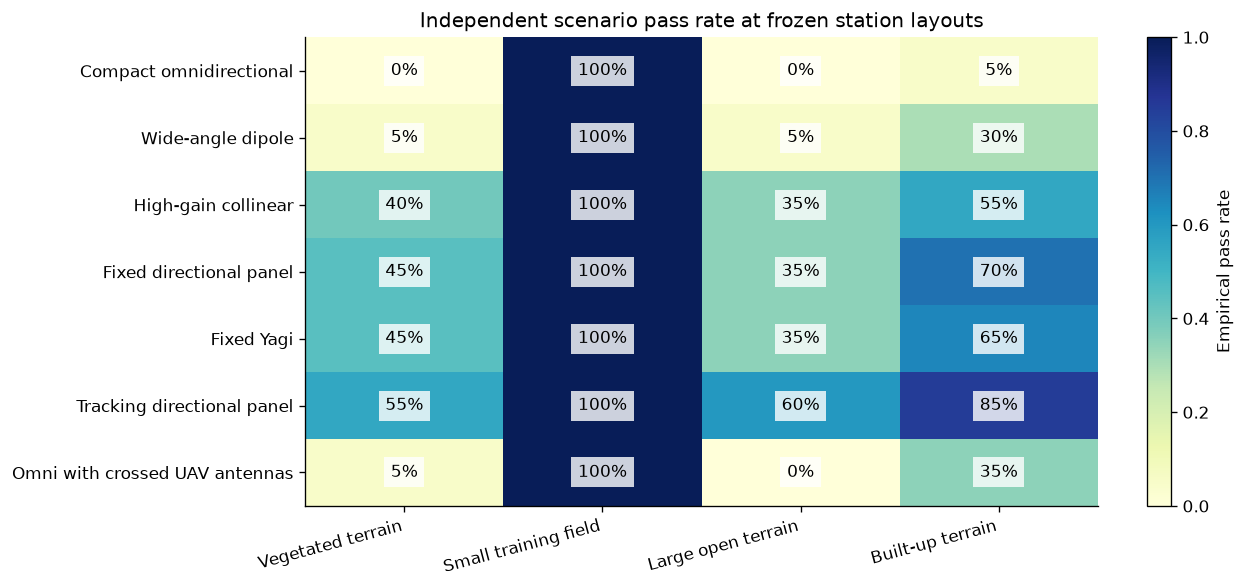

In [6]:
leaders=[]
for p in PROFILES:
    g=comparison[comparison.profile==p['id']]
    eligible=g[g.pass_rate>=.95]
    if len(eligible):row=eligible.sort_values(['complexity','p05_worst'],ascending=[True,False]).iloc[0]
    else:row=g.sort_values(['pass_rate','p05_worst','complexity'],ascending=[False,False,True]).iloc[0]
    c=next(x for x in CONFIGS if x['id']==row.antenna)
    leaders.append(dict(terrain=p['name'],profile=p['id'],antenna=c['name'],antenna_id=c['id'],station=row.site,mast_m=float(row.mast),selection_pass_rate=float(row.pass_rate),independent_pass_rate=float(row.test_pass_rate),mean_reserve_coverage=float(row.test_mean_coverage),worst_reserve_coverage=float(row.test_worst_coverage),worst_p05_margin_db=float(row.test_worst_p05),interpretation='Simplest configuration meeting the selection criterion' if len(eligible) else 'Strongest relative performer; not a universal suitability claim'))
leaders=pd.DataFrame(leaders);display(leaders.round(3))
leaders.to_csv(OUT/'terrain_findings.csv',index=False)
(OUT/'terrain_findings.json').write_text(json.dumps(leaders.to_dict('records'),indent=2,allow_nan=False))
fig,ax=plt.subplots(figsize=(11,5))
heat=comparison.pivot(index='antenna',columns='profile',values='test_pass_rate').reindex([c['id'] for c in CONFIGS])
im=ax.imshow(heat.values,vmin=0,vmax=1,cmap='YlGnBu',aspect='auto')
ax.set_yticks(range(len(heat)),[c['name'] for c in CONFIGS]);ax.set_xticks(range(len(heat.columns)),[next(p['name'] for p in PROFILES if p['id']==k) for k in heat.columns],rotation=15,ha='right')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):ax.text(j,i,f'{100*heat.iloc[i,j]:.0f}%',ha='center',va='center',bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
ax.set_title('Independent scenario pass rate at frozen station layouts');fig.colorbar(im,ax=ax,label='Empirical pass rate');plt.tight_layout();figure('antenna-terrain-comparison')


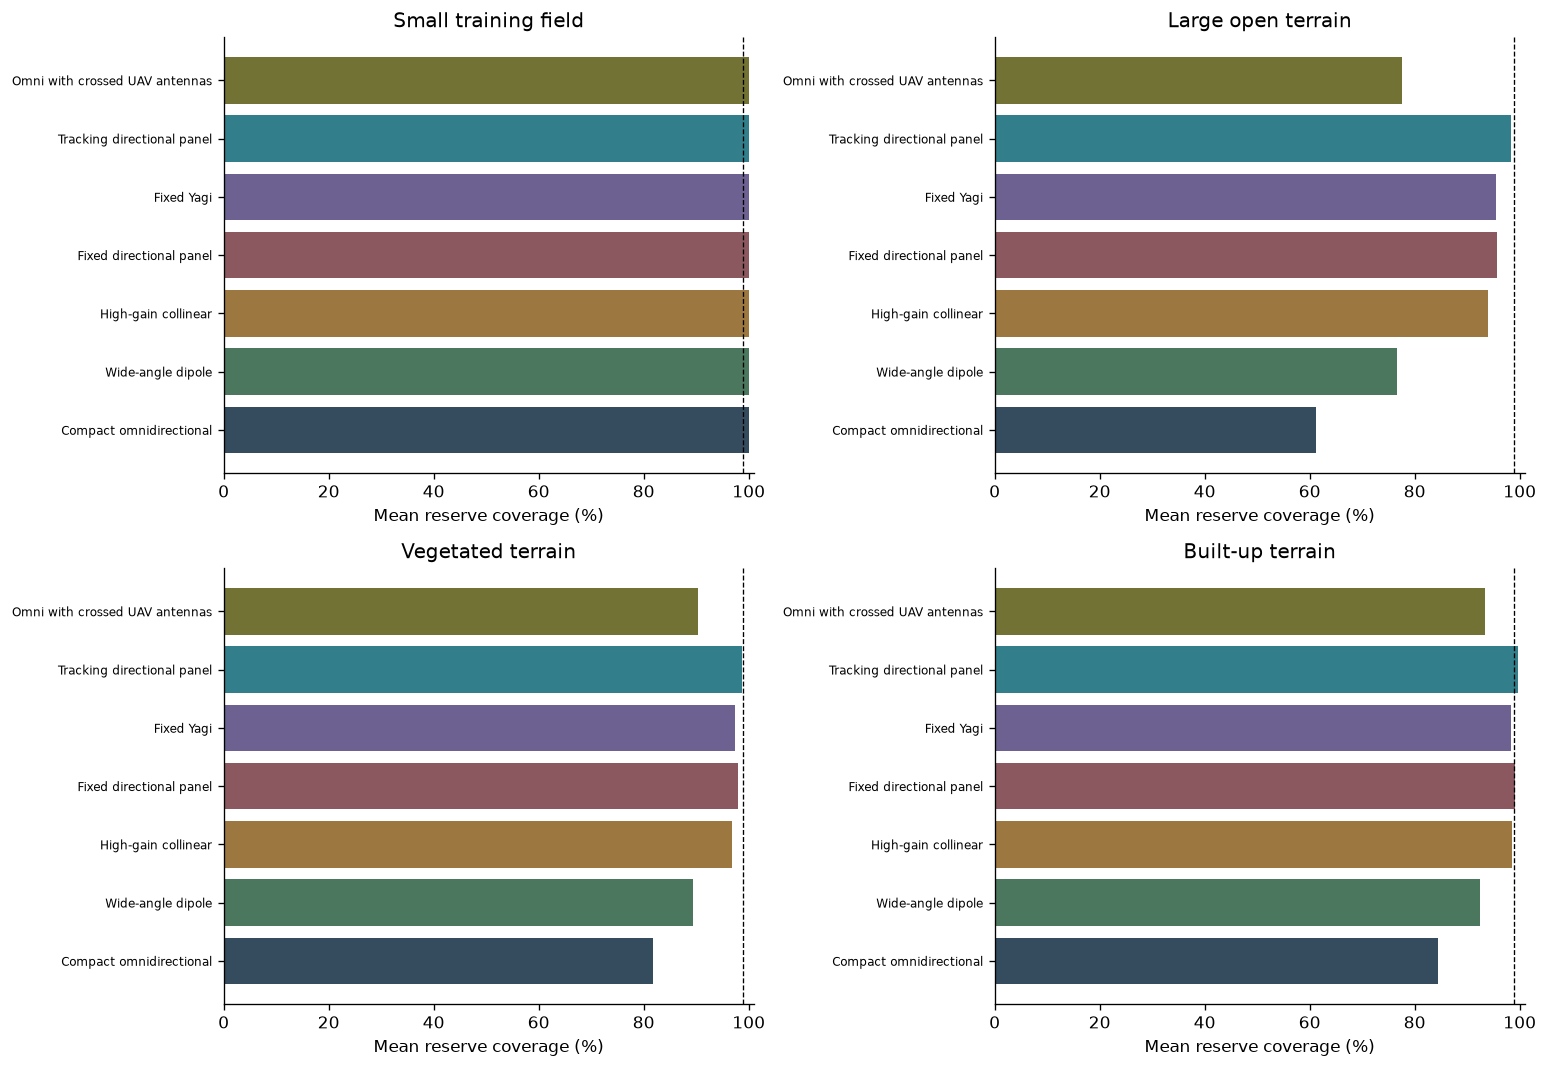

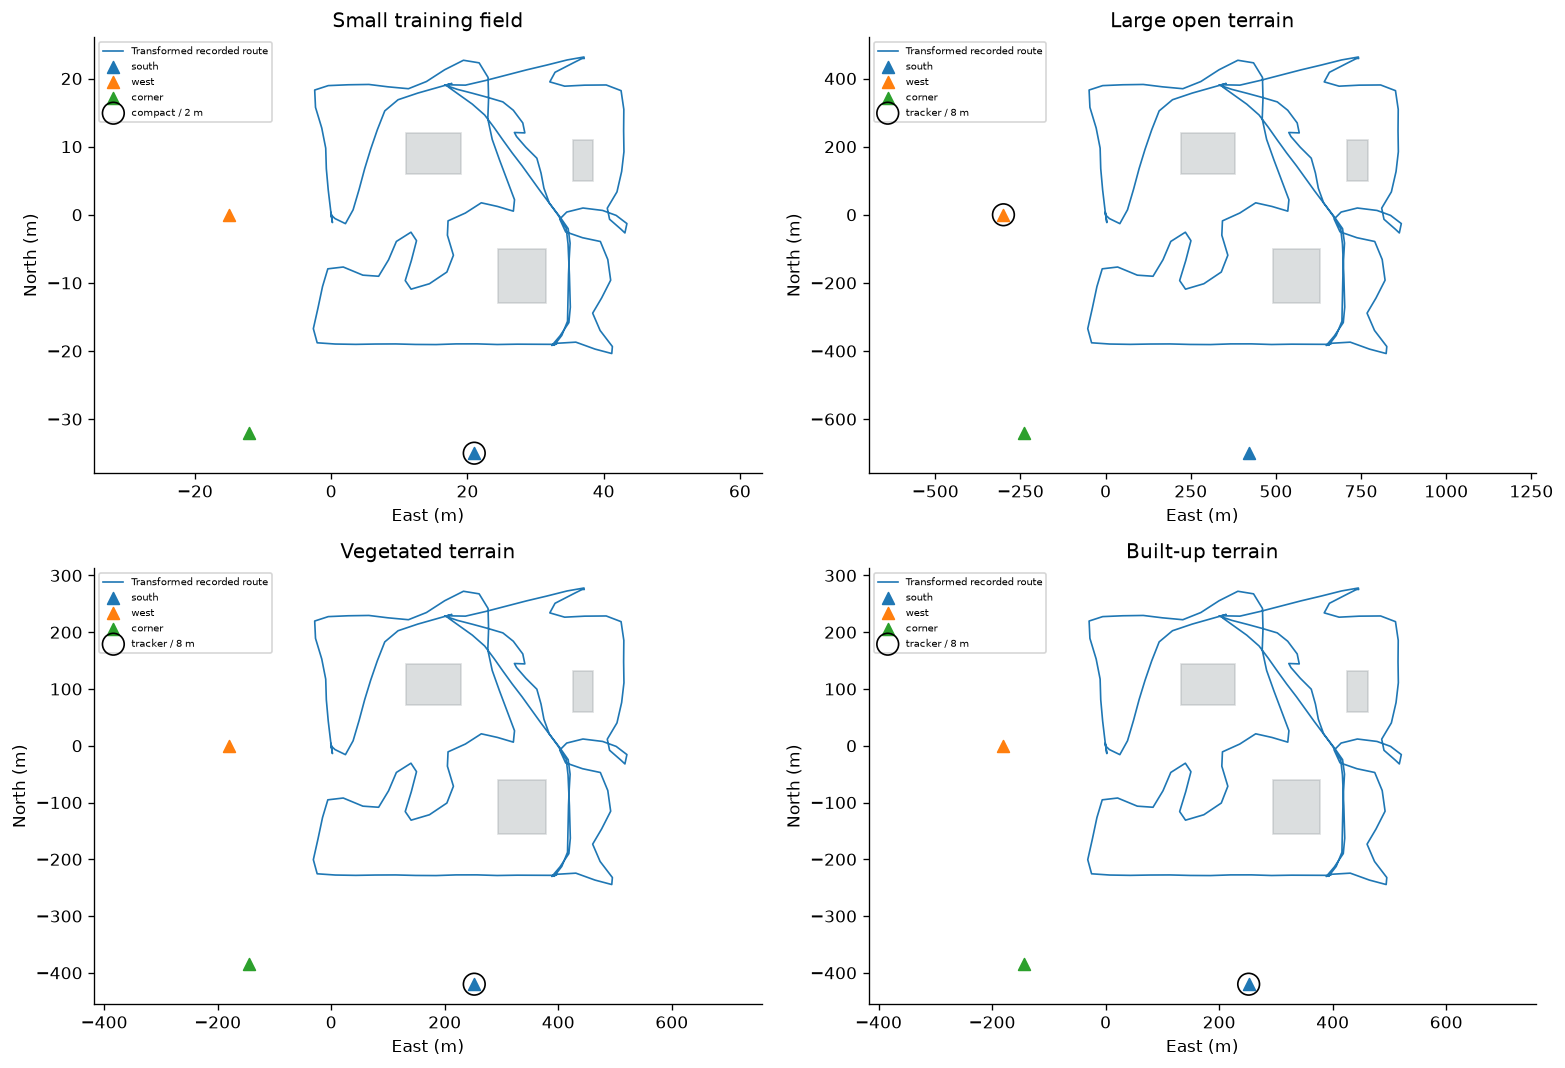

In [7]:
fig,axs=plt.subplots(2,2,figsize=(13,9))
for ax,p in zip(axs.flat,PROFILES):
    g=comparison[comparison.profile==p['id']].set_index('antenna').reindex([c['id'] for c in CONFIGS])
    ax.barh(range(7),g.test_mean_coverage,color=COLORS);ax.set_yticks(range(7),[c['name'] for c in CONFIGS],fontsize=7);ax.set(xlim=(0,101),xlabel='Mean reserve coverage (%)',title=p['name']);ax.axvline(99,color='black',ls='--',lw=.8)
plt.tight_layout();figure('antenna-terrain-coverage')
fig,axs=plt.subplots(2,2,figsize=(13,9))
for ax,p in zip(axs.flat,PROFILES):
    q=mission_geometry(p,'recorded');ax.plot(q['e'],q['n'],lw=1,label='Transformed recorded route')
    for site in sites(p):ax.scatter(site[1],site[2],marker='^',s=50,label=site[0])
    lead=leaders[leaders.profile==p['id']].iloc[0];site=next(x for x in sites(p) if x[0]==lead.station)
    ax.scatter(site[1],site[2],s=170,facecolors='none',edgecolors='black',label=f'{lead.antenna_id} / {lead.mast_m:g} m')
    for a,b,c,d in LOCAL_BOXES:
        s=p['scale'];ax.add_patch(plt.Rectangle((a*s,b*s),(c-a)*s,(d-b)*s,color='#8a9297',alpha=.3))
    ax.set(title=p['name'],xlabel='East (m)',ylabel='North (m)');ax.axis('equal');ax.legend(fontsize=6)
plt.tight_layout();figure('antenna-station-layouts')


## 6. Interpretation
**Small training field:** short distances and broad angular coverage favor a simple omni arrangement. Extra directivity adds installation requirements without necessarily improving the task-level comparison.

**Large open terrain:** ground-side receive directivity can help the weaker UAV→ground direction. A tracking panel follows changing directions; a fixed antenna must keep the route within its beam.

**Vegetated terrain:** the tracking panel can provide useful directional receive gain in this model, while ray-dependent attenuation and shadowing still determine the measured comparison. No antenna is assumed to remove vegetation effects.

**Built-up terrain:** station placement matters alongside antenna type. The tracking panel's relative result is conditional on the modeled obstructions and predefined station options; it is not evidence that it penetrates arbitrary buildings.

The numeric tables are authoritative for this run. The interpretation describes mechanisms, not a promise that the same ranking holds for every site.

## 7. Checks and scope
Physical product selection requires measured radiation patterns, installation/chassis effects and radio specifications. Multipath, exact diffraction, Fresnel clearance, interference, actual modem packet error and video capacity are not solved here. This study does not change MAVLink traffic or flight failsafes.


In [8]:
assert set(SELECTION_SEEDS).isdisjoint(VALIDATION_SEEDS)
assert len(selection)==4*7*3*2*20 and len(test)==4*7*20
assert len(comparison)==28 and len(leaders)==4
assert abs(float(fspl(1000,2400))-100.054)<.02
for p in PROFILES:
    f=FEATURES[(p['id'],'recorded','south',2.)];a=robust_link(f,p,CONFIGS[1],3);b=robust_link(f,p,CONFIGS[1],3,extra_loss=6.)
    np.testing.assert_allclose(a['margin']-b['margin'],6.)
    assert np.isfinite(a['margin']).all()
print('Reproducibility and internal-consistency checks passed.')


Reproducibility and internal-consistency checks passed.


## References
- [ITU-R P.525: free-space attenuation](https://www.itu.int/rec/R-REC-P.525-5-202411-I/en)
- [ArduPilot: antenna tracking](https://ardupilot.org/copter/docs/common-antenna-tracking.html)
- [Taoglas: example 868 MHz collinear antenna datasheet](https://www.taoglas.com/datasheets/OMB.868.B10F21.pdf)

The commercial datasheet illustrates an antenna family; its measured pattern is not imported into this model. Only the self-contained analysis and local simulation geometry are published. The integrated UAV mission, perception and flight-command implementation remains private.
